# Understanding the Lift dataset

**Who this is for:** someone using a robot arm simulator for the first time.

**What you will be able to do after Part 1:**
- Say what `states`, `obs`, `next_obs` and `actions` contain at each time step.
- Say what `reset_to()`, `env.step()`, `sim.forward()` and `get_observation()` do.
- Say which coordinate frame each position and quaternion uses.

**Outline of Part 1**
1. The main words
2. See the episode
3. `states[t]`: the exact simulator state
4. `obs[t]` and `next_obs[t]`
5. `actions[t]`: the commands
6. `reset_to()`
7. `env.step()`, `get_observation()` and `sim.forward()`
8. Frames and quaternions
9. Common mistakes and one exercise

This notebook only reads the dataset file. It never writes to it.

## 1. The main words

| Word | Plain meaning |
| --- | --- |
| **Simulator (MuJoCo)** | A physics program. It calculates how the robot and the cube move. |
| **robosuite** | Builds the Lift task on top of MuJoCo: the robot, table, cube and controller. |
| **robomimic** | Provides the dataset and a small wrapper, `env`, around robosuite. |
| **End-effector (EEF)** | The tool at the tip of the arm. Here it is the gripper. |
| **Episode, or demonstration** | One recorded attempt at the task. `demo_0` is the first one. |
| **Control step** | One decision: the human operator's device gave one new command. Here it lasts 0.05 s, so there are 20 per second. |
| **Physics step** | One small calculation by MuJoCo, lasting 0.002 s. One control step contains 25 physics steps. |
| **Controller** | The program that turns a command such as "move up" into motor forces. |

`t` counts control steps. `N` is the number of recorded actions in the episode.

In [1]:
import os
import sys
from pathlib import Path

# Offscreen rendering needs this setting before robosuite is imported.
os.environ["MUJOCO_GL"] = "egl"
os.environ["PYOPENGL_PLATFORM"] = "egl"

import matplotlib.pyplot as plt
import numpy as np
import robomimic.utils.env_utils as EnvUtils
import robomimic.utils.obs_utils as ObsUtils
from scipy.spatial.transform import Rotation

ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "scripts"))
from inspect_lift_demo import arm_controller, load_demo, restore_model

demo = load_demo(ROOT / "data/robomimic/datasets/lift/ph/low_dim_v15.hdf5", "demo_0")
states, actions, obs, next_obs = demo["states"], demo["actions"], demo["obs"], demo["next_obs"]
N = len(actions)
print("N =", N, "control steps, which is", N * 0.05, "seconds")

N = 59 control steps, which is 2.95 seconds


In [2]:
ObsUtils.initialize_obs_utils_with_obs_specs({"obs": {"low_dim": list(obs), "rgb": []}})
env = EnvUtils.create_env_from_metadata(demo["env_args"], render=False, render_offscreen=True, use_image_obs=False)


def rebuild_scene():
    '''Reload the stored scene and refresh the names that point into the simulator.

    Returns:
        None: Nothing.
    '''
    # Loading a model creates a new simulator object, so names saved earlier become stale.
    global sim, robot, controller, gripper, site_id
    restore_model(env, demo)
    sim = env.env.sim
    robot = env.env.robots[0]
    controller = arm_controller(env)
    gripper = robot.gripper["right"]
    site_id = robot.eef_site_id["right"]


rebuild_scene()

[robosuite WARNING] No private macro file found! (macros.py:53)


[robosuite WARNING] It is recommended to use a private macro file (macros.py:54)


[robosuite WARNING] To setup, run: python /home/abbas/Projects/bezier-rfm/.venv/lib/python3.12/site-packages/robosuite/scripts/setup_macros.py (macros.py:55)



============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'robot0_joint_pos_sin', 'robot0_eef_pos', 'robot0_joint_pos_cos', 'object', 'robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_eef_quat_site', 'robot0_joint_vel', 'robot0_joint_pos']
using obs modality: rgb with keys: []


[robosuite WARNING] Could not import robosuite_models. Some robots may not be available. If you want to use these robots, please install robosuite_models from source (https://github.com/ARISE-Initiative/robosuite_models) or through pip install. (__init__.py:30)


[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly, otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:40)


Created environment with name Lift
Action size is 7


## 2. See the episode

The file has no images. To make a picture, we put the simulator into a stored state and take a photo. No time passes and no action runs.

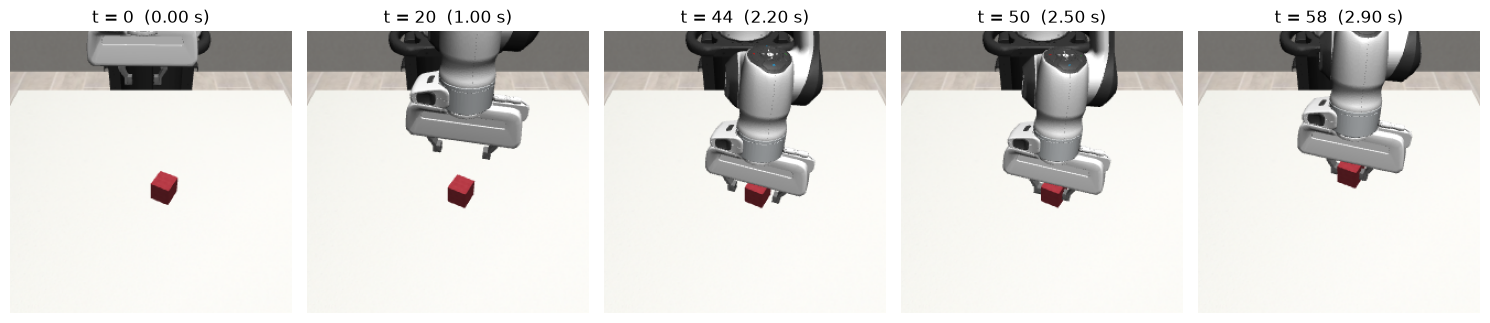

In [3]:
key_steps = [0, 20, 44, 50, 58]
fig, axes = plt.subplots(1, len(key_steps), figsize=(15, 3.4))
for ax, t in zip(axes, key_steps):
    env.reset_to({"states": states[t]})
    ax.imshow(env.render(mode="rgb_array", height=256, width=256, camera_name="agentview"))
    ax.set_title(f"t = {t}  ({t * 0.05:.2f} s)")
    ax.axis("off")
plt.tight_layout()
plt.show()

The arm reaches down, closes on the cube, and lifts it. The whole demonstration lasts about 3 seconds.

## 3. `states[t]`: the exact simulator state

`states[t]` is the information MuJoCo needs to continue the physics. It has 32 numbers:

| Part | Size | Meaning |
| --- | --- | --- |
| time | 1 | Simulator clock, in seconds |
| `qpos` | 16 | Positions: 7 arm joint angles, 2 finger positions, 3 for cube position, 4 for cube rotation |
| `qvel` | 15 | Velocities of those same parts |

The cube has 4 position-like numbers for rotation but only 3 velocity numbers for rotation. That is why `qpos` has 16 and `qvel` has 15.

`states` does **not** directly contain the end-effector pose. The simulator calculates that from the joint angles.

In [4]:
s = states[20]
print("time        ", np.round(s[0], 3))
print("arm joints  ", np.round(s[1:8], 3))
print("fingers     ", np.round(s[8:10], 3))
print("cube pos    ", np.round(s[10:13], 3))
print("cube quat   ", np.round(s[13:17], 3))
print("all velocity", np.round(s[17:], 3).shape)
print("time between stored states:", np.round(np.diff(states[:, 0])[:3], 3), "seconds")

time         1.0
arm joints   [ 0.041  0.643  0.003 -2.065 -0.072  2.726  1.085]
fingers      [ 0.039 -0.039]
cube pos     [0.026 0.027 0.821]
cube quat    [0.247 0.    0.    0.969]
all velocity (15,)
time between stored states: [0.05 0.05 0.05] seconds


## 4. `obs[t]` and `next_obs[t]`

An **observation** is a set of readable measurements, such as "where is the gripper?". Each key has one row per time step.

The recording order is:

```
obs[t]  --->  actions[t]  --->  next_obs[t]
what the      what the          what was true after
robot saw     operator sent     that action finished
```

The next step starts where this step ended. So `next_obs[t]` and `obs[t+1]` describe **the same moment**. The two arrays differ in one way:

- `obs` covers the moments 0 to N-1.
- `next_obs` covers the moments 1 to N.

Only `next_obs[N-1]` shows the moment after the final action. Dataset loaders keep both so each row is a full (before, action, after) sample.

Largest difference between next_obs[t] and obs[t+1]: 0.0


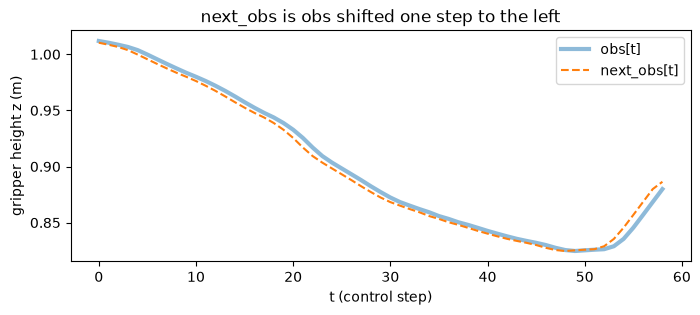

In [5]:
key = "robot0_eef_pos"
print("Largest difference between next_obs[t] and obs[t+1]:", np.abs(next_obs[key][:-1] - obs[key][1:]).max())

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(obs[key][:, 2], label="obs[t]", lw=3, alpha=0.5)
ax.plot(next_obs[key][:, 2], "--", label="next_obs[t]")
ax.set(xlabel="t (control step)", ylabel="gripper height z (m)", title="next_obs is obs shifted one step to the left")
ax.legend()
plt.show()

## 5. `actions[t]`: the commands

`actions[t]` has 7 numbers. Each one lies between -1 and 1. They come from the human operator's input device.

| Index | Meaning | Value of 1.0 means |
| --- | --- | --- |
| 0, 1, 2 | Move along world x, y, z | Aim 0.05 m away from the current position |
| 3, 4, 5 | Rotate about world x, y, z | Aim 0.5 rad away from the current orientation |
| 6 | Gripper | +1 closes, -1 opens |

**The key idea:** an action is a *target*, not a movement. The arm chases the target for 0.05 s and usually does not reach it. Each new action sets a fresh target from wherever the gripper is at that moment. This is what `goal_update_mode = achieved` means.

The plot below shows the difference between the commanded distance and the distance the gripper really moved.

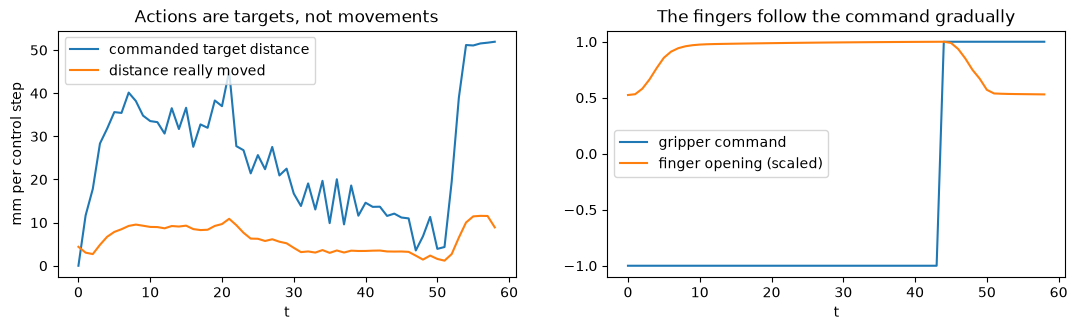

Median commanded 22.5 mm, median moved 5.7 mm
First closing command at t = 44


In [6]:
commanded = np.linalg.norm(actions[:, :3] * 0.05, axis=1)
moved = np.linalg.norm(next_obs["robot0_eef_pos"] - obs["robot0_eef_pos"], axis=1)
gap = states[:, 8] - states[:, 9]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
axes[0].plot(commanded * 1000, label="commanded target distance")
axes[0].plot(moved * 1000, label="distance really moved")
axes[0].set(xlabel="t", ylabel="mm per control step", title="Actions are targets, not movements")
axes[0].legend()
axes[1].plot(actions[:, 6], label="gripper command")
axes[1].plot(gap / gap.max(), label="finger opening (scaled)")
axes[1].set(xlabel="t", title="The fingers follow the command gradually")
axes[1].legend()
plt.show()
print(f"Median commanded {np.median(commanded) * 1000:.1f} mm, median moved {np.median(moved) * 1000:.1f} mm")
print("First closing command at t =", int(np.argmax(actions[:, 6] > 0)))

Step 2 of the project needs this idea. An "absolute action" is the target pose written directly, instead of as a distance from the current pose.

## 6. `reset_to()`: jump to a stored moment

`env.reset_to({"states": states[t]})` works like opening a saved game:

1. It copies time, `qpos` and `qvel` into the simulator.
2. It calls `sim.forward()` so that all calculated values match the new positions.
3. It returns a fresh observation.

No time passes and no physics runs. If you also pass `"model": model_file`, it first rebuilds the whole scene from the stored description.

**What it does not restore:** anything outside the 32 numbers. The gripper keeps a private running value, `current_action`, that moves by 0.2 per control step toward open or closed. `reset_to` leaves it unchanged.

In [7]:
reset_obs = env.reset_to({"states": states[30]})
print("Stored and restored gripper position differ by:", np.abs(reset_obs["robot0_eef_pos"] - obs["robot0_eef_pos"][30]).max())

print("\nGripper private value during a short test:")
print("  now:", gripper.current_action)
for t in range(46, 50):
    env.reset_to({"states": states[t]})
    env.step(actions[t])
print("  after 4 closing commands:", gripper.current_action)
env.reset_to({"states": states[0]})
print("  after jumping back to t = 0:", gripper.current_action, " <- not restored")
rebuild_scene()
print("  after rebuilding the scene:", gripper.current_action)

Stored and restored gripper position differ by: 2.220446049250313e-16

Gripper private value during a short test:
  now: [0.]


  after 4 closing commands: [-0.8  0.8]
  after jumping back to t = 0: [-0.8  0.8]  <- not restored


  after rebuilding the scene: [0.]


This is why the replay check in `inspect_lift_demo.py` could match the arm almost exactly, but not always the fingers.

## 7. `env.step()`, `get_observation()` and `sim.forward()`

These three functions do different jobs.

| Function | Does time pass? | What it does |
| --- | --- | --- |
| `env.step(action)` | Yes, 0.05 s | Runs the controller and 25 physics steps, then returns an observation |
| `sim.forward()` | No | Recalculates values from the current joint angles, such as where the gripper is in space |
| `env.get_observation()` | No | Reads the sensors again, using whatever values the simulator currently holds |

**Why a read can be slightly old.** The simulator keeps two kinds of numbers:

- **Primary values:** joint angles and velocities.
- **Calculated values:** for example, the gripper position in space, worked out from the joint angles.

A physics step calculates the second kind first, and then moves the joints. So at the end of a step, the joints have moved but the calculated gripper position has not caught up. `sim.forward()` fixes this.

Think of a car's dashboard that updates just before the car moves on. `sim.forward()` refreshes the dashboard without moving the car.

The next cell plays the recorded actions in order and compares three reads.

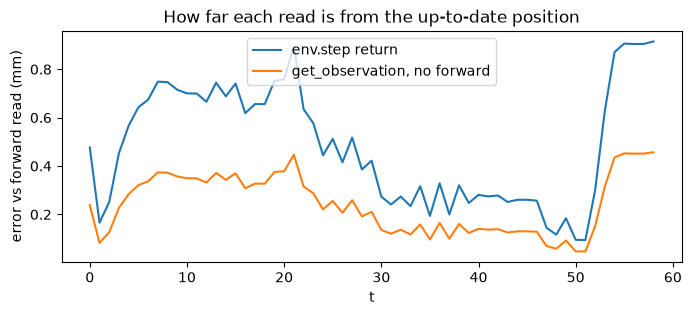

env.step return:  median 0.45 mm, max 0.91 mm
get_observation:  median 0.23 mm, max 0.46 mm


In [8]:
def true_eef_pos():
    '''Return the end-effector position after recalculating the simulator values.

    Returns:
        np.ndarray: Position in the world frame, shape (3,).
    '''
    sim.forward()
    return sim.data.site_xpos[site_id].copy()


# First run: only look at what env.step returned.
rebuild_scene()
step_return_error = []
for t in range(N):
    returned = env.step(actions[t])[0]["robot0_eef_pos"]
    step_return_error.append(np.linalg.norm(returned - true_eef_pos()))

# Second run: only look at get_observation, before calling forward.
rebuild_scene()
get_obs_error = []
for t in range(N):
    env.step(actions[t])
    read = env.get_observation()["robot0_eef_pos"].copy()
    get_obs_error.append(np.linalg.norm(read - true_eef_pos()))

step_return_error, get_obs_error = np.array(step_return_error) * 1000, np.array(get_obs_error) * 1000
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(step_return_error, label="env.step return")
ax.plot(get_obs_error, label="get_observation, no forward")
ax.set(xlabel="t", ylabel="error vs forward read (mm)", title="How far each read is from the up-to-date position")
ax.legend()
plt.show()
print(f"env.step return:  median {np.median(step_return_error):.2f} mm, max {step_return_error.max():.2f} mm")
print(f"get_observation:  median {np.median(get_obs_error):.2f} mm, max {get_obs_error.max():.2f} mm")

The stored dataset matches the `sim.forward()` read, because the replay check found errors near 1e-16 m when no contact was involved. A policy running in the simulator would normally receive the `env.step` return. We should remember this small difference when we reach execution.

## 8. Frames and quaternions

A **frame** is a set of three perpendicular axes attached to something, like a small x-y-z marker. A pose has two parts: where the frame's origin is, and how its axes point.

A **quaternion** is 4 numbers that describe a rotation. Here, each quaternion answers: "how is this frame rotated relative to the world frame?"

| Frame | Attached to | Where you meet it |
| --- | --- | --- |
| **World** | The room. It never moves. | All stored positions and quaternions use it. Actions also use its axes. |
| **Robot base** | The bottom of the arm | Same axes as the world, but a different origin |
| **Grip site** | A marked point between the fingers | `robot0_eef_pos`, `robot0_eef_quat_site`, and the controller |
| **Hand body** | The arm's last part, called `robot0_right_hand` | `robot0_eef_quat` |
| **Cube** | The cube | `obs["object"]`, and `qpos` inside `states` |

**Quaternions you can read:**

| Source | Frame | Number order |
| --- | --- | --- |
| `robot0_eef_quat` | Hand body | x, y, z, w |
| `robot0_eef_quat_site` | Grip site | x, y, z, w |
| `object[3:7]`, named `cube_quat` | Cube | x, y, z, w |
| `states[t][13:17]` | Cube | **w, x, y, z** |

Note the mismatch: the position `robot0_eef_pos` belongs to the grip site, but `robot0_eef_quat` belongs to the hand body. They do not describe one single frame.

In [9]:
env.reset_to({"states": states[0]})

print("Same cube rotation in two number orders:")
print("  object[3:7]    (x, y, z, w):", np.round(obs["object"][0, 3:7], 3))
print("  states[13:17]  (w, x, y, z):", np.round(states[0, 13:17], 3))

body = Rotation.from_quat(obs["robot0_eef_quat"])
site = Rotation.from_quat(obs["robot0_eef_quat_site"])
offset = body.inv() * site
print("\nRotation from hand body to grip site, in degrees about (x, y, z):", np.round(np.degrees(offset[0].as_rotvec()), 2))
print("Change of that rotation over the episode, in degrees:", np.degrees((offset[0].inv() * offset).magnitude()).max().round(6))

controller.update(force=True)
ref = Rotation.from_matrix(controller.ref_ori_mat)
print("\nController frame versus grip site, degrees:", np.degrees((ref.inv() * site[0]).magnitude()).round(5))
print("Controller frame versus hand body, degrees:", np.degrees((ref.inv() * body[0]).magnitude()).round(5))
print("Distance from hand body origin to grip site, m:", np.linalg.norm(sim.data.get_body_xpos("robot0_right_hand") - obs["robot0_eef_pos"][0]).round(4))
print("Robot base position in the world, m:", sim.data.get_body_xpos("robot0_base").round(3))

Same cube rotation in two number orders:
  object[3:7]    (x, y, z, w): [0.    0.    0.969 0.247]
  states[13:17]  (w, x, y, z): [0.247 0.    0.    0.969]

Rotation from hand body to grip site, in degrees about (x, y, z): [ -0.  -0. -90.]
Change of that rotation over the episode, in degrees: 2.1e-05

Controller frame versus grip site, degrees: 0.0
Controller frame versus hand body, degrees: 90.0
Distance from hand body origin to grip site, m: 0.097
Robot base position in the world, m: [-0.56   0.     0.912]


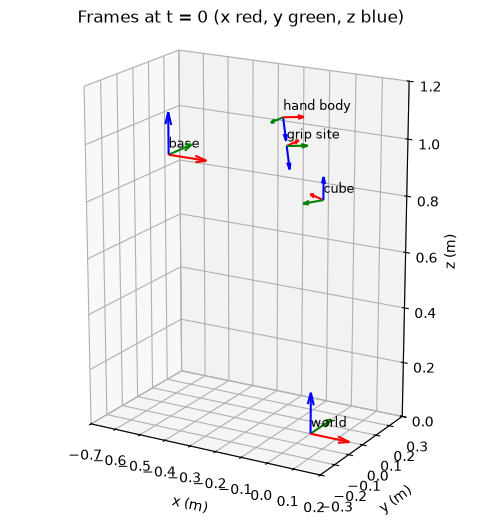

In [10]:
def draw_frame(ax, position, rotation, name, length=0.08):
    '''Draw one frame as red, green and blue arrows for its x, y and z axes.

    Args:
        ax (Axes3D): Plot axes.
        position (np.ndarray): Frame origin, shape (3,).
        rotation (Rotation): Frame orientation in the world frame.
        name (str): Label for the frame.
        length (float): Arrow length in meters.

    Returns:
        None: Nothing.
    '''
    for axis, color in zip(rotation.as_matrix().T, "rgb"):
        ax.quiver(*position, *(axis * length), color=color)
    ax.text(*(position + np.array([0, 0, 0.025])), name, fontsize=9)


fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
identity = Rotation.identity()
draw_frame(ax, np.zeros(3), identity, "world", 0.15)
draw_frame(ax, sim.data.get_body_xpos("robot0_base").copy(), identity, "base", 0.15)
draw_frame(ax, sim.data.get_body_xpos("robot0_right_hand").copy(), body[0], "hand body")
draw_frame(ax, obs["robot0_eef_pos"][0], site[0], "grip site")
draw_frame(ax, obs["object"][0, :3], Rotation.from_quat(obs["object"][0, 3:7]), "cube")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", xlim=(-0.7, 0.2), ylim=(-0.3, 0.3), zlim=(0, 1.2), title="Frames at t = 0 (x red, y green, z blue)")
ax.set_box_aspect((0.9, 0.6, 1.2))
ax.view_init(18, -60)
plt.show()

**What this means for our method.** The controller works in the grip site frame. Curves on SO(3) × R³ should use one frame for position and orientation, so the grip site is the natural choice. The hand body differs from it by a fixed rotation that never changes, so we can convert between them exactly.

## 9. Common mistakes and one exercise

**Common mistakes**
- Treating an action as the movement that happened. It is only a target.
- Building a pose from `robot0_eef_pos` and `robot0_eef_quat`. These belong to different frames.
- Copying a quaternion between `states` and `obs` without changing the number order.
- Assuming `reset_to` restores everything. It restores only the 32 stored numbers.

**Exercise.** Use `obs["object"]` to find the first step where the cube is more than 1 cm above its starting height. Is this before or after the first closing command? The cube height is `object[:, 2]`.

In [11]:
# One possible answer.
height = obs["object"][:, 2]
raised = int(np.argmax(height > height[0] + 0.01))
closing = int(np.argmax(actions[:, 6] > 0))
print(f"Cube passes 1 cm at t = {raised}, first closing command at t = {closing}")

Cube passes 1 cm at t = 56, first closing command at t = 44


# Part 2: from delta actions to absolute actions

Part 1 explained the recorded dataset. Part 2 explains the new file that `scripts/convert_lift_abs.py` made from it, and why it is built that way.

**What you will be able to do after Part 2:**
- Say what a delta action and an absolute action are, and how to change one into the other.
- Say why adding up the deltas gives the wrong answer.
- Say why a rotation vector can jump when the rotation itself does not.
- Say why the new file needs different controller settings.

**Outline of Part 2**

10. The same command in two forms
11. Why we cannot add up the deltas
12. The goal is not where the gripper is
13. Rotation vectors can jump
14. The file must name the correct controller
15. What changed in the file
16. Common mistakes and one exercise

This part reads both dataset files and writes to neither. It does not test whether absolute actions reproduce the original motion. Step 3 tests that.

## 10. The same command in two forms

Think of giving directions to a walker.

- **Delta action:** "Walk 5 m north from where you are now." The instruction only makes sense if you know where the walker is.
- **Absolute action:** "Walk to the post box." The instruction names the destination itself.

For the arm, the conversion uses the current grip-site pose. The numbers 0.05 and 0.5 are the controller limits from section 5:

$$p^{goal}_t = p_t + 0.05\,a^{pos}_t \qquad\qquad R^{goal}_t = \exp(0.5\,a^{rot}_t)\,R_t$$

The gripper command stays as it is. The absolute action is 7 numbers: goal position (3), goal rotation vector (3), gripper (1).

The next cell works one step by hand, and compares the result with the controller and with the new file. The new file stores the goals in the world frame, for the grip site.

In [12]:
import json

import h5py
from convert_lift_abs import demo_keys, make_env

ABS_PATH = ROOT / "data/robomimic/datasets/lift/ph/low_dim_abs.hdf5"
with h5py.File(ABS_PATH, "r") as f:
    abs_actions = f["data/demo_0/actions"][:]
    abs_env_args = json.loads(f["data"].attrs["env_args"])
    delta_env_args = json.loads(f["data"].attrs["env_args_delta"])
    action_convention = json.loads(f["data"].attrs["action_convention"])

goal_pos, goal_rot = abs_actions[:, :3], Rotation.from_rotvec(abs_actions[:, 3:6])
print("Absolute actions shape:", abs_actions.shape)

Absolute actions shape: (59, 7)


In [13]:
t = 20
rebuild_scene()
env.reset_to({"states": states[t]})
controller.update(force=True)
controller.set_goal(actions[t, :6])

by_hand = obs["robot0_eef_pos"][t] + 0.05 * actions[t, :3]
print("Current position      ", np.round(obs["robot0_eef_pos"][t], 4))
print("Delta action (pos)    ", np.round(actions[t, :3], 4))
print("Goal by hand          ", np.round(by_hand, 4))
print("Goal from controller  ", np.round(controller.goal_pos, 4))
print("Goal in the new file  ", np.round(abs_actions[t, :3], 4))

rotation_by_hand = Rotation.from_rotvec(0.5 * actions[t, 3:6]) * Rotation.from_quat(obs["robot0_eef_quat_site"][t])
print("\nRotation: by hand vs new file, degrees:", np.degrees((rotation_by_hand.inv() * goal_rot[t]).magnitude()).round(5))

Current position       [0.023  0.0261 0.9328]
Delta action (pos)     [ 0.388 -0.007 -0.63 ]
Goal by hand           [0.0424 0.0257 0.9013]
Goal from controller   [0.0424 0.0257 0.9013]
Goal in the new file   [0.0424 0.0257 0.9013]

Rotation: by hand vs new file, degrees: 0.0


All three goal positions agree, and so does the rotation. Over all demonstrations, the largest rotation difference is 7e-7 rad. The stored site quaternion uses float32 numbers, which is the likely cause.

The script reads the goal from the controller. It does not call `robot.control` or run any physics, so nothing moves. The formula above is only an independent check.

## 11. Why we cannot add up the deltas

A natural idea is to start at the first position and add up all the deltas. That would be correct only if the arm reached every target.

Section 5 showed that it does not. Each action starts again from where the gripper **really is**, not from the previous target. So adding up the deltas counts movement that never happened.

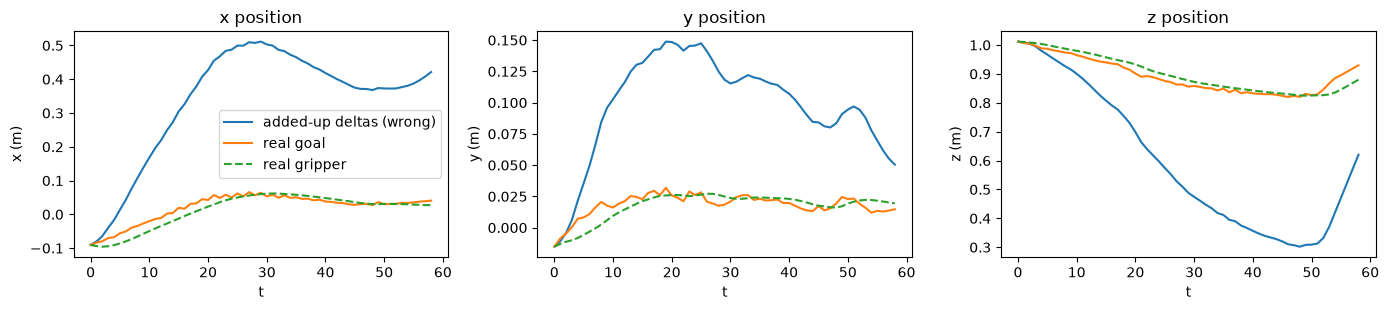

Added-up deltas end 49.2 cm from the real final goal


In [14]:
added_up = obs["robot0_eef_pos"][0] + np.cumsum(actions[:, :3] * 0.05, axis=0)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharex=True)
for i, (ax, name) in enumerate(zip(axes, "xyz")):
    ax.plot(added_up[:, i], label="added-up deltas (wrong)")
    ax.plot(goal_pos[:, i], label="real goal")
    ax.plot(obs["robot0_eef_pos"][:, i], "--", label="real gripper")
    ax.set(xlabel="t", ylabel=f"{name} (m)", title=f"{name} position")
axes[0].legend()
plt.tight_layout()
plt.show()
print(f"Added-up deltas end {np.linalg.norm(added_up[-1] - goal_pos[-1]) * 100:.1f} cm from the real final goal")

## 12. The goal is not where the gripper is

The new file stores **targets**, not the path the gripper followed. The target stays ahead of the gripper while the arm moves, like a carrot on a stick. When the arm moves slowly, the two come close together.

This matters for later steps: a curve fitted to goals describes what the controller was asked to do, not what the gripper did.

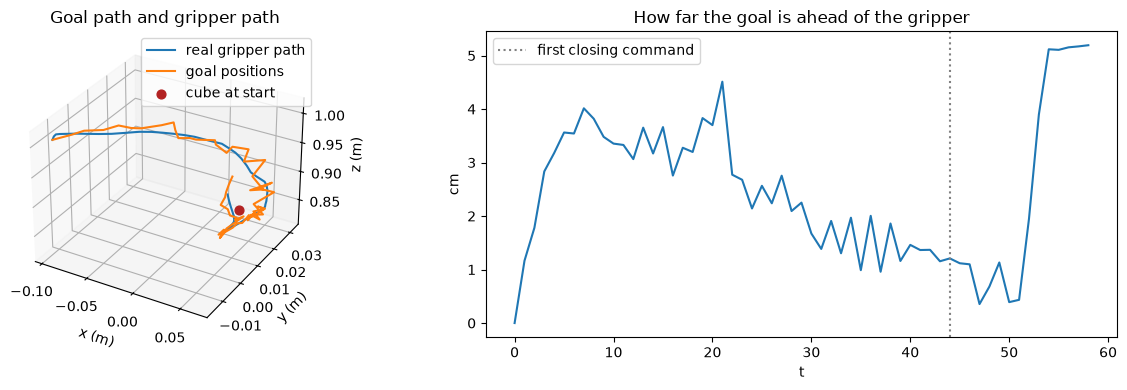

Goal ahead of gripper: median 2.3 cm, max 5.2 cm


In [15]:
gripper_path = obs["robot0_eef_pos"]
lead = np.linalg.norm(goal_pos - gripper_path, axis=1) * 100

fig = plt.figure(figsize=(13, 4))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(*gripper_path.T, label="real gripper path")
ax.plot(*goal_pos.T, label="goal positions")
ax.scatter(*obs["object"][0, :3], color="firebrick", s=40, label="cube at start")
ax.set(xlabel="x (m)", ylabel="y (m)", zlabel="z (m)", title="Goal path and gripper path")
ax.legend()
ax = fig.add_subplot(1, 2, 2)
ax.plot(lead)
ax.axvline(44, color="gray", ls=":", label="first closing command")
ax.set(xlabel="t", ylabel="cm", title="How far the goal is ahead of the gripper")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Goal ahead of gripper: median {np.median(lead):.1f} cm, max {lead.max():.1f} cm")

## 13. Rotation vectors can jump

A **rotation vector** stores a rotation in 3 numbers. Its direction is the axis to turn around, and its length is the angle to turn.

The angle only goes up to π (180°), because turning further is the same as turning the other way. So 179° about an axis and 179° about the opposite axis are nearly the same rotation, even though their numbers are far apart.

It is like a clock: 11:59 and 12:01 are 2 minutes apart, but the number on the display jumps a long way.

This matters here because the gripper points **down** and the world's z axis points **up**. The grip site is therefore always close to a 180° rotation from the world frame, right beside the place where the numbers jump.

The next cell finds a demonstration with a jump. It compares the stored numbers with the true rotation change.

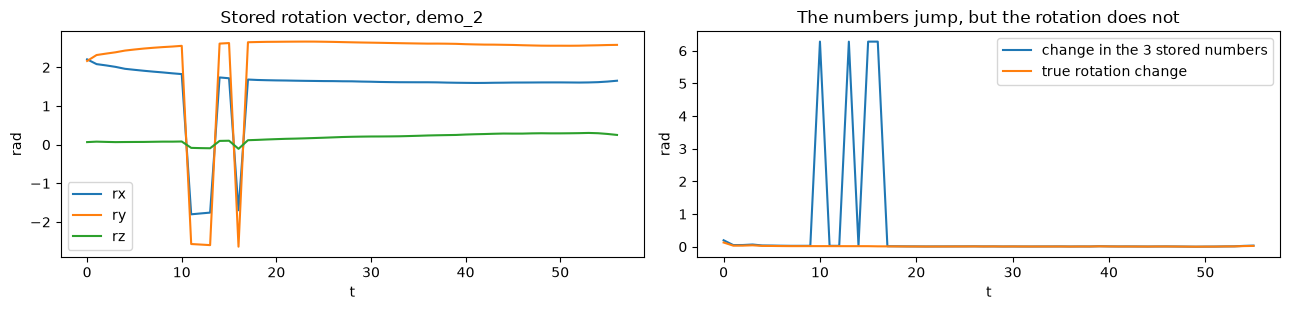

At t = 10 in demo_2:
  stored numbers change by 6.282
  true rotation changes by 0.017 rad


In [16]:
with h5py.File(ABS_PATH, "r") as f:
    for key in demo_keys(f["data"]):
        rotvecs = f[f"data/{key}/actions"][:, 3:6]
        number_change = np.linalg.norm(np.diff(rotvecs, axis=0), axis=1)
        if number_change.max() > 1.0:
            break
rotations = Rotation.from_rotvec(rotvecs)
true_change = (rotations[:-1].inv() * rotations[1:]).magnitude()
jump = int(number_change.argmax())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for i, name in enumerate(["rx", "ry", "rz"]):
    axes[0].plot(rotvecs[:, i], label=name)
axes[0].set(xlabel="t", ylabel="rad", title=f"Stored rotation vector, {key}")
axes[0].legend()
axes[1].plot(number_change, label="change in the 3 stored numbers")
axes[1].plot(true_change, label="true rotation change")
axes[1].set(xlabel="t", ylabel="rad", title="The numbers jump, but the rotation does not")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"At t = {jump} in {key}:")
print(f"  stored numbers change by {number_change[jump]:.3f}")
print(f"  true rotation changes by {true_change[jump]:.3f} rad")

**Why this matters: averaging.** Suppose a method treats the 3 numbers as ordinary coordinates and averages the two rotations on either side of the jump. The next cell compares that with the true halfway rotation.

In [17]:
before, after = rotvecs[jump], rotvecs[jump + 1]
naive_middle = Rotation.from_rotvec((before + after) / 2)
true_middle = Rotation.from_rotvec(before) * Rotation.from_rotvec(0.5 * (Rotation.from_rotvec(before).inv() * Rotation.from_rotvec(after)).as_rotvec())

print("Rotation before:", np.round(before, 3))
print("Rotation after: ", np.round(after, 3))
print(f"Averaging the numbers gives a rotation {np.degrees((naive_middle.inv() * true_middle).magnitude()):.1f} degrees from the true middle")

Rotation before: [1.825 2.556 0.081]
Rotation after:  [-1.802 -2.571 -0.084]
Averaging the numbers gives a rotation 180.0 degrees from the true middle


This is why later steps must not fit curves to these 3 numbers directly. We must turn them into rotations first, and then use our SO(3) operations. The robot itself is not affected, because both sides of a jump are valid rotations.

## 14. The file must name the correct controller

The same 7 numbers mean different things to different controllers. So the new file stores its own controller settings:

| Attribute in the new file | Creates |
| --- | --- |
| `env_args` | Absolute controller |
| `env_args_delta` | The original delta controller |
| `action_convention` | A plain record of frames and units |

The next cells build the absolute controller and give it the stored goal. Then they show what would go wrong if a delta controller received those same numbers. Both tests only set a goal. No physics runs.

In [18]:
arm_settings = abs_env_args["env_kwargs"]["controller_configs"]["body_parts"]["right"]
delta_settings = delta_env_args["env_kwargs"]["controller_configs"]["body_parts"]["right"]
print("env_args:        input_type =", arm_settings.get("input_type"), "| control_delta =", arm_settings.get("control_delta"))
print("env_args_delta:  input_type =", delta_settings.get("input_type"), "| control_delta =", delta_settings.get("control_delta"))
print("\naction_convention:")
for name, value in action_convention.items():
    print(f"  {name}: {value}")

env_args:        input_type = absolute | control_delta = None
env_args_delta:  input_type = None | control_delta = True

action_convention:
  type: absolute
  position: world-frame grip-site target position (m), actions[:, 0:3]
  orientation: rotation vector of the world-frame grip-site target orientation (rad), actions[:, 3:6]
  gripper: original gripper command, actions[:, 6]
  goal_source: OSC_POSE controller goal_pos and goal_ori after set_goal on the stored delta action
  source_sha256: 2067777cb8b532e9263dd09fd6448c41cc31224bb27be4a3b734010ae13eb540


In [19]:
abs_env = make_env(abs_env_args, obs)
abs_controller = arm_controller(abs_env)

t = 20
abs_env.reset_to({"states": states[t]})
abs_controller.update(force=True)
abs_controller.set_goal(abs_actions[t, :6])
right_error = np.linalg.norm(abs_controller.goal_pos - goal_pos[t])

# The mistake: give the same absolute numbers to the delta controller.
rebuild_scene()
env.reset_to({"states": states[t]})
controller.update(force=True)
controller.set_goal(abs_actions[t, :6])
wrong_error = np.linalg.norm(controller.goal_pos - goal_pos[t])

print(f"Absolute controller goal is {right_error * 100:.4f} cm from the intended goal")
print(f"Delta controller goal is    {wrong_error * 100:.1f} cm from the intended goal")


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'robot0_joint_pos_sin', 'robot0_eef_pos', 'robot0_joint_pos_cos', 'object', 'robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_eef_quat_site', 'robot0_joint_vel', 'robot0_joint_pos']
using obs modality: rgb with keys: []


Created environment with name Lift
Action size is 7


Absolute controller goal is 0.0000 cm from the intended goal
Delta controller goal is    7.9 cm from the intended goal


With the wrong controller, there is no error message. The robot simply receives a wrong target. This is why the new file's `env_args` creates the absolute controller by itself.

## 15. What changed in the file

Only the first six action columns and the metadata changed. The next cell checks `demo_0`. `scripts/validate_lift_abs.py` runs the same comparison on all 200 demonstrations.

In [20]:
source_path = ROOT / "data/robomimic/datasets/lift/ph/low_dim_v15.hdf5"
with h5py.File(source_path, "r") as a, h5py.File(ABS_PATH, "r") as b:
    d0, d1 = a["data/demo_0"], b["data/demo_0"]
    print("Pose actions changed:      ", not np.array_equal(d0["actions"][:, :6], d1["actions"][:, :6]))
    print("Gripper commands identical:", np.array_equal(d0["actions"][:, 6], d1["actions"][:, 6]))
    print("States identical:          ", np.array_equal(d0["states"][:], d1["states"][:]))
    print("All obs identical:         ", all(np.array_equal(d0["obs"][k][:], d1["obs"][k][:]) for k in d0["obs"]))
    print("All next_obs identical:    ", all(np.array_equal(d0["next_obs"][k][:], d1["next_obs"][k][:]) for k in d0["next_obs"]))

print("\nOne action, t = 20")
print("  delta:   ", np.round(actions[20], 3))
print("  absolute:", np.round(abs_actions[20], 3))

Pose actions changed:       True
Gripper commands identical: True
States identical:           True
All obs identical:          True
All next_obs identical:     True

One action, t = 20
  delta:    [ 0.388 -0.007 -0.63  -0.038 -0.01  -0.12  -1.   ]
  absolute: [ 0.042  0.026  0.901  2.44   1.896 -0.016 -1.   ]


## 16. Common mistakes and one exercise

**Common mistakes**
- Adding up deltas to find the goal. Each delta starts from the real gripper pose.
- Treating goals as the path the gripper followed. Goals stay ahead of it.
- Averaging or fitting rotation vectors as if they were ordinary coordinates.
- Giving absolute actions to a delta controller. No error appears.
- Clipping absolute actions to the range -1 to 1. These values are meters and radians, so clipping would destroy them.

**Exercise.** Find the step in `demo_0` where the goal is farthest ahead of the gripper. Then look at `actions[t, :3]` at that step. Is the largest number close to 1? Use `lead` from section 12.

In [21]:
# One possible answer.
farthest = int(lead.argmax())
print(f"Farthest at t = {farthest}, {lead[farthest]:.2f} cm ahead")
print("Delta position command there:", np.round(actions[farthest, :3], 3))

Farthest at t = 58, 5.19 cm ahead
Delta position command there: [ 0.264 -0.095  1.   ]


# Part 3: do the two action forms move the robot the same way?

Part 2 showed that delta and absolute actions give the controller the same **target**. Part 3 asks the next question: does the robot then **move** the same way?

**What you will be able to do after Part 3:**
- Say what a one-step test measures, and what it cannot measure.
- Say why the first step after loading a model behaves differently.
- Read the Experiment A results across all 200 demonstrations.
- Say why tiny differences can grow when the gripper touches the cube.
- Say which results are settled and which are still open.

**Outline of Part 3**

17. One step, two controllers
18. The stale first step
19. Results across all 200 demonstrations
20. Why contact steps go over the limit
21. Comparing with the recording
22. The final `next_obs` row
23. What is settled, what is open, and one exercise

Sections 19, 21, 22 and the exercise read the saved results of `scripts/experiment_a_one_step.py`. They do not rerun all 200 demonstrations, which takes about 7 minutes.

## 17. One step, two controllers

Think of two identical robots in two separate simulators. We put both in exactly the same recorded moment. We then give one the delta action and the other the absolute action, let 0.05 s pass (25 physics steps), and compare them.

```
                  delta action    ---> next state A
recorded state <                                        compare A and B
                  absolute action ---> next state B
```

Before every step, both robots go back to a recorded state. This means an error cannot build up over time, so each comparison tests one step only.

**What this test cannot show:** whether the whole task still works when small errors are allowed to build up. Step 4 tests that.

In [22]:
from experiment_a_one_step import METRICS, THRESHOLDS, compare_results, load_demo_model, one_step

with h5py.File(source_path, "r") as f:
    demo_0_group = f["data/demo_0"]
    load_demo_model(env, demo_0_group)
    load_demo_model(abs_env, demo_0_group)

# Run the steps in order, so the gripper's private value builds up as it did in the recording.
for t in range(21):
    delta_result = one_step(env, states[t], actions[t])
    abs_result = one_step(abs_env, states[t], abs_actions[t])

print("After one step from t = 20")
print("  delta controller, gripper position:   ", np.round(delta_result["pos"], 6))
print("  absolute controller, gripper position:", np.round(abs_result["pos"], 6))
print("  recording, next gripper position:     ", np.round(next_obs["robot0_eef_pos"][20], 6))
print()
for name, value in zip(METRICS, compare_results(delta_result, abs_result)):
    print(f"  {name:12s} delta vs absolute: {value:.1e}")

After one step from t = 20
  delta controller, gripper position:    [0.029276 0.026145 0.925486]
  absolute controller, gripper position: [0.029276 0.026145 0.925486]
  recording, next gripper position:      [0.029276 0.026145 0.925486]

  eef_pos_m    delta vs absolute: 8.4e-13
  eef_rot_rad  delta vs absolute: 2.8e-12
  arm_q        delta vs absolute: 2.1e-12
  finger_q     delta vs absolute: 7.1e-16
  cube_q       delta vs absolute: 5.0e-19
  arm_v        delta vs absolute: 6.1e-11
  finger_v     delta vs absolute: 3.5e-16
  cube_v       delta vs absolute: 2.3e-16


The names in this list are the parts of the state we compare:

| Name | Meaning | Unit |
| --- | --- | --- |
| `eef_pos_m`, `eef_rot_rad` | Grip-site position and rotation | m, rad |
| `arm_q`, `arm_v` | Arm joint angles and joint speeds | rad, rad/s |
| `finger_q`, `finger_v` | Finger positions and speeds | m, m/s |
| `cube_q`, `cube_v` | Cube position and rotation, and cube speeds | m and quaternion, m/s and rad/s |

We read the pose after `sim.forward()`, for the reason given in section 7.

## 18. The stale first step

A controller saves its reading of the gripper pose, and it updates that reading only when a flag called `new_update` is `True`.

Right after a model load, that flag is `False`. `reset_to` then moves the robot, but the controller does not notice. So the first step uses an **old pose**, like a map showing where you were a moment ago. After that first step, the flag works normally.

We can fix this by setting `new_update = True` after `reset_to`. Experiment A calls this a **refreshed** step, and calls the other kind **stale**.

In [23]:
with h5py.File(source_path, "r") as f:
    demo_0_group = f["data/demo_0"]
    load_demo_model(env, demo_0_group)
    env.reset_to({"states": states[0]})
    stale_controller = arm_controller(env)
    print("new_update after reset_to:", stale_controller.new_update)
    print("Pose the controller believes:", np.round(stale_controller.ref_pos, 4))
    print("Real gripper position:       ", np.round(obs["robot0_eef_pos"][0], 4))
    print(f"Gap: {np.linalg.norm(stale_controller.ref_pos - obs['robot0_eef_pos'][0]) * 100:.2f} cm")

    results = {}
    for refresh in (False, True):
        load_demo_model(env, demo_0_group)
        load_demo_model(abs_env, demo_0_group)
        results[refresh] = (one_step(env, states[0], actions[0], refresh), one_step(abs_env, states[0], abs_actions[0], refresh))

arm_v = METRICS.index("arm_v")
print("\nArm joint speed difference after the first step (rad/s)")
print(f"{'':10s}{'delta vs absolute':>20s}{'delta vs recording':>20s}{'absolute vs recording':>24s}")
for refresh, label in ((False, "stale"), (True, "refreshed")):
    d, a = results[refresh]
    recording = {"state": states[1], "pos": obs["robot0_eef_pos"][1], "rot": Rotation.from_quat(obs["robot0_eef_quat_site"][1]).as_matrix()}
    print(f"{label:10s}{compare_results(d, a)[arm_v]:20.1e}{compare_results(d, recording)[arm_v]:20.1e}{compare_results(a, recording)[arm_v]:24.1e}")

new_update after reset_to: False
Pose the controller believes: [-0.1028  0.      1.011 ]
Real gripper position:        [-0.0905 -0.0152  1.0118]
Gap: 1.96 cm



Arm joint speed difference after the first step (rad/s)
             delta vs absolute  delta vs recording   absolute vs recording
stale                  1.1e-01             1.9e-05                 1.1e-01
refreshed              6.2e-11             1.1e-01                 1.1e-01


**How to read this table:**
- **Stale:** delta and absolute disagree, because they use the old pose in different ways.
- **Refreshed:** delta and absolute agree. This is why Experiment A refreshes every step.
- **Stale delta vs recording** is the closest match to the recording. This suggests the recording's first step used the old pose too. We cannot observe the original recording run, so this is an inference.

So the absolute action at `t = 0` is the correct target from the true pose, but it may not be what drove the recording. Across all 200 demonstrations, it misses the recording's next position by a median of 2.7 mm. We will check in Step 4 whether this matters.

## 19. Results across all 200 demonstrations

We set the limits after reviewing `demo_0`, and before running the other 199 demonstrations.

The plots use a logarithmic axis, where each grid step is 10 times larger. Most steps sit far below the limit. A small group lies above it.

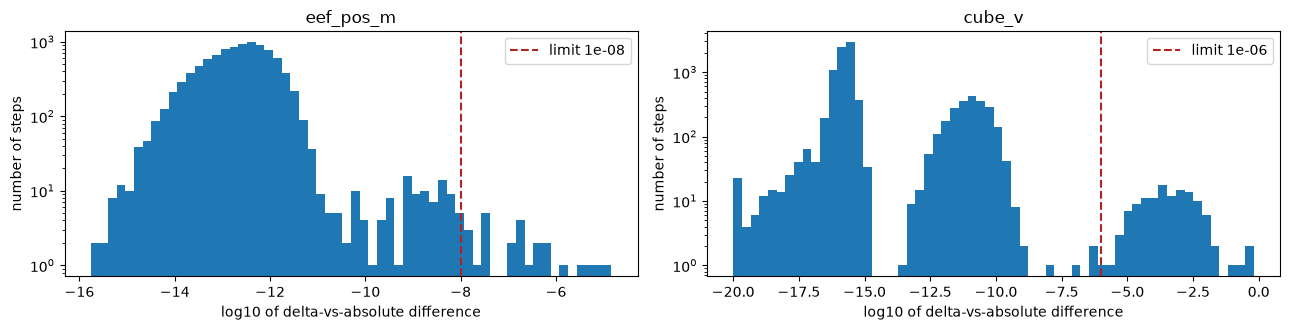

Steps within all limits: 9540 of 9666
Steps over a limit: 126 (1.3%), in 40 of 200 demonstrations

metric          limit    median       max  steps over
eef_pos_m       1e-08   2.4e-13   1.5e-05          25
eef_rot_rad     1e-08   7.8e-13   2.7e-05          32
arm_q           1e-08   6.9e-13   2.9e-05          26
finger_q        1e-08   1.3e-15   7.0e-05         111
cube_q          1e-08   1.3e-18   3.7e-03         126
arm_v           1e-06   2.0e-11   2.2e-03          33
finger_v        1e-06   5.5e-15   1.8e-03         104
cube_v          1e-06   2.3e-16   6.6e-01         124


In [24]:
experiment_a = np.load(ROOT / "docs/one-step-equivalence/results.npz")
a_names = list(experiment_a["metrics"])
a_demo, a_t = experiment_a["demo"], experiment_a["t"]
delta_vs_abs = experiment_a["delta_vs_absolute"]
delta_vs_rec = experiment_a["delta_vs_recording"]
abs_vs_rec = experiment_a["absolute_vs_recording"]
limits = np.array([THRESHOLDS[name] for name in a_names])
over_limit = (delta_vs_abs > limits).any(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
for ax, name in zip(axes, ["eef_pos_m", "cube_v"]):
    j = a_names.index(name)
    # A difference of exactly 0 cannot appear on a logarithmic axis, so show it at the left edge.
    values = np.log10(np.maximum(delta_vs_abs[:, j], 1e-20))
    ax.hist(values, bins=60)
    ax.axvline(np.log10(limits[j]), color="firebrick", ls="--", label=f"limit {limits[j]:.0e}")
    ax.set_yscale("log")
    ax.set(xlabel="log10 of delta-vs-absolute difference", ylabel="number of steps", title=name)
    ax.legend()
plt.tight_layout()
plt.show()

print(f"Steps within all limits: {(~over_limit).sum()} of {len(over_limit)}")
print(f"Steps over a limit: {over_limit.sum()} ({over_limit.mean() * 100:.1f}%), in {len(set(a_demo[over_limit]))} of {len(set(a_demo))} demonstrations\n")
print(f"{'metric':12s}{'limit':>9s}{'median':>10s}{'max':>10s}{'steps over':>12s}")
for j, name in enumerate(a_names):
    print(f"{name:12s}{limits[j]:9.0e}{np.median(delta_vs_abs[:, j]):10.1e}{delta_vs_abs[:, j].max():10.1e}{(delta_vs_abs[:, j] > limits[j]).sum():12d}")

**Result:** the experiment did not fully meet the limits we set. We keep those limits and report this directly. The next section looks at the steps over the limit.

## 20. Why contact steps go over the limit

**Contact is sensitive.** Free motion behaves like a ball rolling on a smooth floor: start it slightly differently and it ends slightly differently. Contact is more like a pencil balanced on its tip, where a tiny push can decide what happens next. In the simulator, contact forces can switch on or off when a distance changes by a tiny amount.

We test this on `demo_55`, which has the largest cube speed difference. Three other runs are compared with a normal delta run:

| Run | Difference from the normal delta run |
| --- | --- |
| **Repeat** | None. It is the same delta action again. |
| **Tiny change** | The delta action changes by 1e-12, which moves the target by about 5e-14 m. |
| **Absolute** | The action is in absolute form. |

If the conversion caused the large values, the tiny change should stay small. If contact sensitivity caused them, the tiny change should look like the absolute run.


============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'robot0_joint_pos_sin', 'robot0_eef_pos', 'robot0_joint_pos_cos', 'object', 'robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_eef_quat_site', 'robot0_joint_vel', 'robot0_joint_pos']
using obs modality: rgb with keys: []
Created environment with name Lift
Action size is 7

============= Initialized Observation Utils with Obs Spec =============

using obs modality: low_dim with keys: ['robot0_gripper_qvel', 'robot0_joint_pos_sin', 'robot0_eef_pos', 'robot0_joint_pos_cos', 'object', 'robot0_eef_quat', 'robot0_gripper_qpos', 'robot0_eef_quat_site', 'robot0_joint_vel', 'robot0_joint_pos']
using obs modality: rgb with keys: []


Created environment with name Lift
Action size is 7


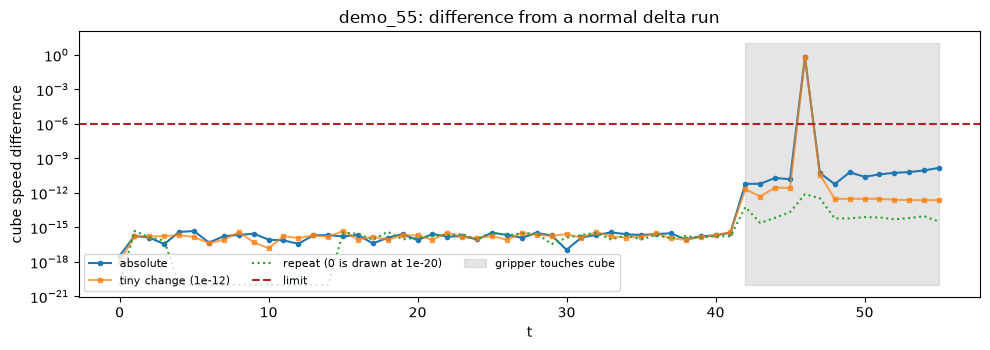

At t = 46: repeat 7.7e-13, tiny change 6.6e-01, absolute 6.6e-01


In [25]:
key = "demo_55"
tiny_env = make_env(delta_env_args, obs)
repeat_env = make_env(delta_env_args, obs)
cube_v = a_names.index("cube_v")

with h5py.File(source_path, "r") as f, h5py.File(ABS_PATH, "r") as g:
    group = f[f"data/{key}"]
    s55, a55, abs55 = group["states"][:], group["actions"][:], g[f"data/{key}/actions"][:]
    for one_env in (env, abs_env, tiny_env, repeat_env):
        load_demo_model(one_env, group)

touching, to_repeat, to_tiny, to_absolute = [], [], [], []
for t in range(len(a55)):
    env.reset_to({"states": s55[t]})
    touching_gripper = env.env.robots[0].gripper["right"]
    touch_before = env.env.check_contact(touching_gripper, env.env.cube)
    normal = one_step(env, s55[t], a55[t])
    touching.append(touch_before or env.env.check_contact(touching_gripper, env.env.cube))
    tiny_action = a55[t].copy()
    tiny_action[:6] += 1e-12
    to_repeat.append(compare_results(normal, one_step(repeat_env, s55[t], a55[t]))[cube_v])
    to_tiny.append(compare_results(normal, one_step(tiny_env, s55[t], tiny_action))[cube_v])
    to_absolute.append(compare_results(normal, one_step(abs_env, s55[t], abs55[t]))[cube_v])
touching = np.array(touching)
to_repeat, to_tiny, to_absolute = np.array(to_repeat), np.array(to_tiny), np.array(to_absolute)

fig, ax = plt.subplots(figsize=(10, 3.6))
floor = 1e-20
ax.semilogy(np.maximum(to_absolute, floor), "o-", ms=3, label="absolute")
ax.semilogy(np.maximum(to_tiny, floor), "s-", ms=3, alpha=0.7, label="tiny change (1e-12)")
ax.semilogy(np.maximum(to_repeat, floor), ":", label=f"repeat (0 is drawn at {floor:.0e})")
ax.axhline(THRESHOLDS["cube_v"], color="firebrick", ls="--", label="limit")
ax.fill_between(np.arange(len(touching)), floor, 10, where=touching, color="gray", alpha=0.2, label="gripper touches cube")
ax.set(xlabel="t", ylabel="cube speed difference", title=f"{key}: difference from a normal delta run")
ax.legend(ncol=3, fontsize=8, loc="lower left")
plt.tight_layout()
plt.show()

worst = int(to_absolute.argmax())
print(f"At t = {worst}: repeat {to_repeat[worst]:.1e}, tiny change {to_tiny[worst]:.1e}, absolute {to_absolute[worst]:.1e}")

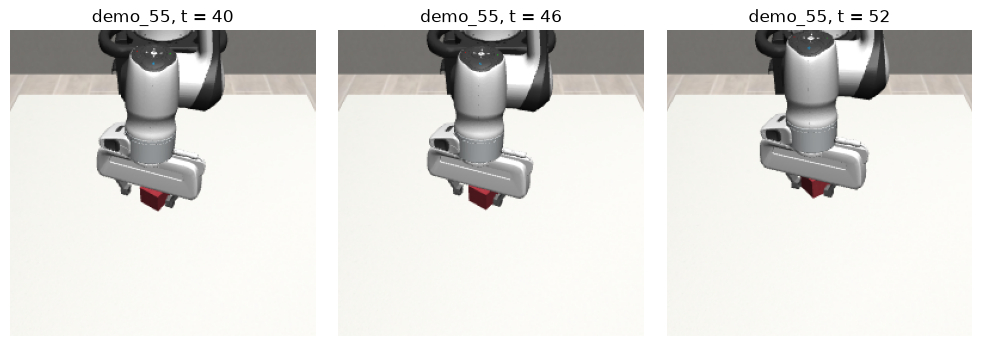

In [26]:
frames = [worst - 6, worst, min(worst + 6, len(s55) - 1)]
with h5py.File(source_path, "r") as f:
    load_demo_model(env, f[f"data/{key}"])
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
for ax, t in zip(axes, frames):
    env.reset_to({"states": s55[t]})
    ax.imshow(env.render(mode="rgb_array", height=256, width=256, camera_name="agentview"))
    ax.set_title(f"{key}, t = {t}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In `demo_55`, the cube speed difference spikes at one step, t = 46, where the gripper is touching the cube. The tiny-change run reaches the same size as the absolute run, while the repeat stays near 1e-12. The difference then falls again, so it did not persist in this test, where each step restarts from a recorded state.

The repeat is not exactly 0 here, unlike the `demo_0` control. A likely reason is that this cell's normal run also does an extra `reset_to` for the contact check, but I did not test this.

The saved one-off checks covered 30 of the 40 affected demonstrations, and found the following:

| Check | Result |
| --- | --- |
| Over-limit steps with the gripper touching the cube | All 126 |
| Other steps with the gripper touching the cube, in those 40 demonstrations | 20% |
| Over-limit steps caused by a 1e-12 delta change alone | 97, with the same largest cube speed difference (0.66) |
| Over-limit steps with the absolute controller given the delta controller's exact goal | 75, with a lower maximum (0.011) |

**What this suggests:** contact magnifies tiny numerical differences, so these values look like simulator sensitivity, not a conversion error. The last row shows that a part of the difference does not come from the goal values at all. The cause is not isolated. Simulator memory left by earlier steps is a possible source.

## 21. Comparing with the recording

We also compare each controller with the recording. This tells us where a difference comes from:

- If both controllers disagree with the recording **by the same amount**, the conversion is not the cause.
- If only the absolute controller disagrees, the conversion is the likely cause.

In the plot, each dot is one step. A dot on the diagonal means both controllers are the same distance from the recording.

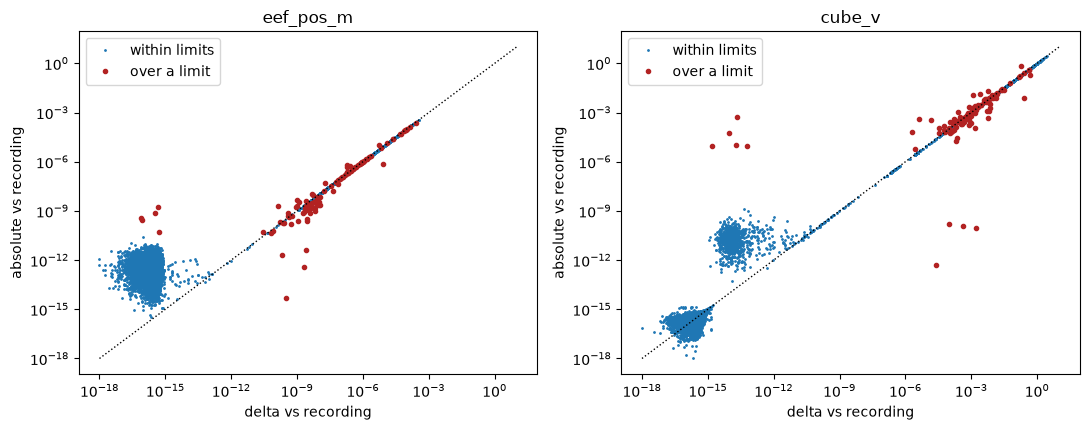

Steps other than the first and final, difference from the recording
  eef_pos_m  delta: median 2.7e-16, max 3.6e-04 | absolute: median 5.7e-13, max 3.6e-04
  arm_q      delta: median 1.7e-16, max 7.3e-04 | absolute: median 1.6e-12, max 7.3e-04
  arm_v      delta: median 3.3e-15, max 3.1e-02 | absolute: median 4.8e-11, max 3.1e-02
  cube_v     delta: median 2.9e-16, max 2.8e+00 | absolute: median 3.0e-16, max 2.8e+00

At over-limit steps, delta vs absolute is smaller than delta vs recording at 68.5% of steps (cube speed).


In [27]:
pos_j = a_names.index("eef_pos_m")
is_first = a_t == 0
is_final = np.r_[a_t[1:] == 0, True]
middle = ~is_first & ~is_final

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, name in zip(axes, ["eef_pos_m", "cube_v"]):
    j = a_names.index(name)
    x, y = np.maximum(delta_vs_rec[middle, j], 1e-18), np.maximum(abs_vs_rec[middle, j], 1e-18)
    over = over_limit[middle]
    ax.loglog(x[~over], y[~over], ".", ms=2, label="within limits")
    ax.loglog(x[over], y[over], "o", ms=3, color="firebrick", label="over a limit")
    ax.loglog([1e-18, 10], [1e-18, 10], "k:", lw=1)
    ax.set(xlabel="delta vs recording", ylabel="absolute vs recording", title=name)
    ax.legend()
plt.tight_layout()
plt.show()

print("Steps other than the first and final, difference from the recording")
for name in ("eef_pos_m", "arm_q", "arm_v", "cube_v"):
    j = a_names.index(name)
    print(f"  {name:10s} delta: median {np.nanmedian(delta_vs_rec[middle, j]):.1e}, max {np.nanmax(delta_vs_rec[middle, j]):.1e} | absolute: median {np.nanmedian(abs_vs_rec[middle, j]):.1e}, max {np.nanmax(abs_vs_rec[middle, j]):.1e}")

valid = over_limit & ~np.isnan(delta_vs_rec[:, cube_v])
share = np.mean(delta_vs_abs[valid, cube_v] < delta_vs_rec[valid, cube_v])
print(f"\nAt over-limit steps, delta vs absolute is smaller than delta vs recording at {share * 100:.1f}% of steps (cube speed).")

Most dots lie on the diagonal. At low values, near 1e-13 and below, the dots spread away from it because the numbers are at rounding level. Away from these values, delta and absolute have the same gap to the recording.

Even the original delta controller does not exactly reproduce the recording at contact, which agrees with section 20. The last line shows that this comparison alone does not settle the question: at some over-limit steps, delta and absolute differ from each other by more than delta differs from the recording.

## 22. The final `next_obs` row

Section 4 said `next_obs[t]` and `obs[t+1]` describe the same moment. We could only check that up to the second-to-last row, because `obs[N]` does not exist.

Experiment A can now check the final row by simulating the final step. The result is that the final row does not match the simulated next pose in any demonstration.

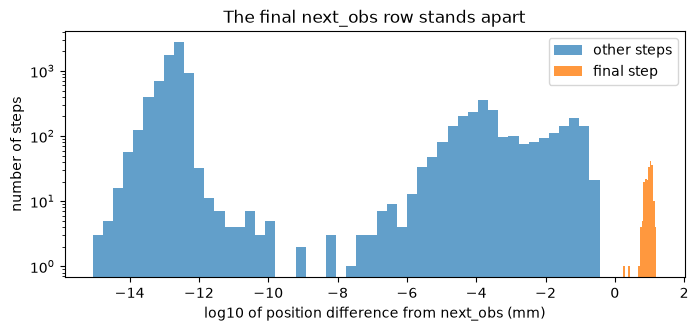

Final step: median 10.0 mm, smallest 1.8 mm
Other steps: median 2.7e-13 mm, max 0.36 mm

In demo_7, the final next_obs row is 0.000 mm from the final obs row, although an action was applied.


In [28]:
final_pos = delta_vs_rec[is_final, pos_j] * 1000
other_pos = delta_vs_rec[~is_final & ~is_first, pos_j] * 1000

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(np.log10(np.maximum(other_pos, 1e-16)), bins=50, alpha=0.7, label="other steps")
ax.hist(np.log10(final_pos), bins=20, alpha=0.8, label="final step")
ax.set_yscale("log")
ax.set(xlabel="log10 of position difference from next_obs (mm)", ylabel="number of steps", title="The final next_obs row stands apart")
ax.legend()
plt.show()
print(f"Final step: median {np.median(final_pos):.1f} mm, smallest {final_pos.min():.1f} mm")
print(f"Other steps: median {np.median(other_pos):.1e} mm, max {other_pos.max():.2f} mm")

with h5py.File(source_path, "r") as f:
    stored = np.linalg.norm(f["data/demo_7/next_obs/robot0_eef_pos"][-1] - f["data/demo_7/obs/robot0_eef_pos"][-1]) * 1000
print(f"\nIn demo_7, the final next_obs row is {stored:.3f} mm from the final obs row, although an action was applied.")

**What to do:** do not use `next_obs[-1]` as a target. All earlier `next_obs` rows match `obs[t+1]` exactly, so this affects only the final row of each demonstration. We have not found why this row differs.

## 23. What is settled, what is open, and one exercise

**Settled**
- Away from gripper-cube contact, delta and absolute give the same next state, to rounding level.
- Before any step, the controller must refresh after a model load, or the first step uses an old pose.
- Repeating the same delta action in a second environment gave a difference of exactly 0 in `demo_0`, so the simulator repeats itself there.

**Open**
- 126 contact steps exceed the limits we set. H16 is logged as confirmed away from contact, with the limits unchanged.
- The tiny-change test points to contact sensitivity, but it covered 30 of the 40 affected demonstrations.
- Some of the contact difference remains even with identical goals. Its source is not isolated.
- The `t = 0` target differs from what seems to have driven the recording.

**What Step 4 adds:** it stops restoring recorded states and runs whole episodes. It will show whether these small differences change the outcome: is the cube still lifted?

**Common mistakes**
- Comparing the first step after a model load without a refresh.
- Reading a pose right after a step without `sim.forward()`.
- Setting limits from one demonstration without allowing for more contact events.
- Treating a difference from the recording as a conversion error, before comparing both controllers.

**Exercise.** Use `over_limit`, `a_demo` and `a_t` to find which demonstration has the most over-limit steps, and list those steps.

In [29]:
# One possible answer.
names, counts = np.unique(a_demo[over_limit], return_counts=True)
most = names[counts.argmax()]
print(most, "has", counts.max(), "over-limit steps, at t =", a_t[over_limit & (a_demo == most)].tolist())

demo_91 has 11 over-limit steps, at t = [26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]


# Part 4: does a whole episode still work?

Part 3 tested one step at a time. Before each step, the robot went back to a recorded state, so an error could not grow. Part 4 removes that safety net. The robot starts from the recorded first state **once**, and then runs every action in order, like a real policy does.

**What you will be able to do after Part 4:**
- Say why a delta replay keeps an early error and an absolute replay removes it.
- Read the four replays of `demo_0` and their errors over time.
- Use the controller's goal log to tell an input problem from a tracking problem.
- Read the results across all 200 demonstrations, including the failures.
- Say why the file keeps its current `t = 0` goal.

**Outline of Part 4**

24. From one step to a whole episode
25. Why delta keeps an error and absolute removes it
26. Four replays of `demo_0`
27. Errors over time
28. The goal log
29. Watch the replay
30. Results across all 200 demonstrations
31. The failed replays
32. Which `t = 0` goal should the file keep?
33. What is settled, what is open, and one exercise

Sections 26 to 28, 31 and 32 run the simulator, and each takes a few seconds to a minute. Sections 29 and 30 read the saved outputs of `scripts/experiment_b_continuous.py`. The run on all 200 demonstrations takes about 25 minutes, so the notebook does not repeat it.

## 24. From one step to a whole episode

Experiment B runs four **replays** of each demonstration. A replay restores the recorded first state `s_0`, and then runs all the stored actions without restoring again.

| Replay | Actions | First step |
| --- | --- | --- |
| `delta_stale` | delta | stale: the controller uses the old pose (section 18) |
| `delta_refreshed` | delta | refreshed: the controller reads the true pose first |
| `absolute_stale` | absolute | stale |
| `absolute_refreshed` | absolute | refreshed |

We then compare three pairs at every step: **recording vs delta**, **recording vs absolute**, and **delta vs absolute**. The replay's pose after action `t` is compared with recorded state `t + 1`.

**The question changes.** In Part 3, the question was "are the next states equal to rounding level?". Here small errors can grow, especially at contact (section 20). So we do not use the `1e-8` limits. The main question is: **is the cube still lifted?** Lift counts the cube as lifted when its centre is more than 4 cm above the table top.

## 25. Why delta keeps an error and absolute removes it

The two controllers build their goal from different things:

$$
\text{delta:}\quad p_\text{goal} = p_\text{now} + 0.05\,a_t
\qquad\qquad
\text{absolute:}\quad p_\text{goal} = p_\text{recorded} + 0.05\,a_t
$$

- The **delta** goal starts from where the robot **is now**. If the robot is 5 mm off the recording, every later goal is also 5 mm off. The error stays.
- The **absolute** goal was computed once, from where the robot **was in the recording**. If the robot is 5 mm off, the next goal still points at the recorded path, so the controller pulls the robot back. The error fades.

Think of two hikers. One follows instructions like "walk 10 steps north", so an early wrong turn shifts the whole route. The other follows map coordinates, so after a wrong turn, the next coordinate brings them back to the path.

**What this means for our comparison:** delta and absolute replays should **not** match closely, even when the conversion is correct. If the replay drifts, the absolute replay should stay closer to the recording than the delta replay.

## 26. Four replays of `demo_0`

`run_demo` reads the recording, then runs the four replays. It returns, for every replay, the state after each step, the controller's goal at each step, and whether the cube is lifted.

In [30]:
from experiment_b_continuous import EPISODES, phase_lines, run_demo

replay_envs = {"delta": env, "absolute": abs_env}
with h5py.File(source_path, "r") as f, h5py.File(ABS_PATH, "r") as g:
    b0 = run_demo(replay_envs, f["data/demo_0"], g["data/demo_0"], video=False)

table_height = float(env.env.model.mujoco_arena.table_offset[2])
recording_b0 = b0["recording"]
print("Recording: first contact at state", int(np.argmax(recording_b0["contact"])), "| first lifted at state", int(np.argmax(recording_b0["success"])))
print()
print(f"{'replay':20s}{'cube lifted at the end':>24s}{'final cube height (cm)':>24s}")
for name in EPISODES:
    run = b0["runs"][name]
    print(f"{name:20s}{str(bool(run['success'][-1])):>24s}{(run['state'][-1, 12] - table_height) * 100:24.2f}")

Recording: first contact at state 48 | first lifted at state 55

replay                cube lifted at the end  final cube height (cm)
delta_stale                             True                    8.76
delta_refreshed                         True                    8.79
absolute_stale                          True                    8.77
absolute_refreshed                      True                    8.77


All four replays lift the cube to about 8.8 cm, well above the 4 cm rule. Now we look at how close each replay stays to the recording along the way.

The phase of each step comes from the recording:

| Phase | Steps |
| --- | --- |
| first | `t = 0` |
| approach | until the gripper first touches the cube |
| grasp | from first contact until the cube first meets the lift rule |
| lift | from that point to the second-to-last step |
| final | the last step, which has no recorded next state |

## 27. Errors over time

The plot shows the grip-site position error at every step. The axis is logarithmic, so each grid line is 10 times larger than the one below. The dashed vertical lines mark phase changes.

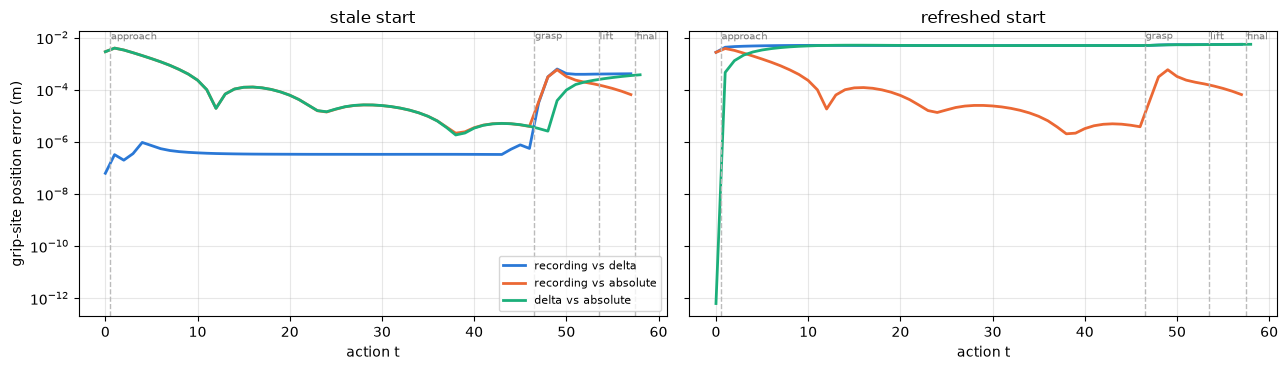

stale     recording vs delta       first step   0.000 mm | approach median  0.0003 mm
stale     recording vs absolute    first step   2.854 mm | approach median  0.0251 mm
stale     delta vs absolute        first step   2.854 mm | approach median  0.0252 mm
refreshed recording vs delta       first step   2.703 mm | approach median  4.9197 mm
refreshed recording vs absolute    first step   2.703 mm | approach median  0.0242 mm
refreshed delta vs absolute        first step   0.000 mm | approach median  4.9169 mm


In [31]:
pair_colors = {"recording_vs_delta": "#2a78d6", "recording_vs_absolute": "#eb6834", "delta_vs_absolute": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, start in zip(axes, ["stale", "refreshed"]):
    for pair, color in pair_colors.items():
        # Values of exactly 0 cannot appear on a logarithmic axis, so draw them at 1e-16.
        ax.semilogy(np.maximum(b0["errors"][f"{start}/{pair}"][:, 0], 1e-16), color=color, lw=2, label=pair.replace("_", " "))
    phase_lines(ax, b0["phase"])
    ax.set(xlabel="action t", title=f"{start} start")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("grip-site position error (m)")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

for start in ["stale", "refreshed"]:
    for pair in pair_colors:
        e = b0["errors"][f"{start}/{pair}"][:, 0]
        approach = b0["phase"] == "approach"
        print(f"{start:10s}{pair.replace('_', ' '):24s} first step {e[0] * 1000:7.3f} mm | approach median {np.median(e[approach]) * 1000:7.4f} mm")

**How to read the plot:**
- **Stale start, recording vs delta (blue, left):** about 1e-7 m until the gripper touches the cube. The stale delta replay is a near-exact copy of the recording, so the recording itself used the stale first step. Part 3 could only infer this. Here we observe it directly.
- **Refreshed start, recording vs delta (blue, right):** about 5 mm from the first step to the end. The first step goes somewhere slightly different, and the delta controller never corrects it (section 25).
- **Absolute, both starts (orange):** about 3 mm off after the first step, and then the error fades during the approach. This error comes from the stored `t = 0` goal. Section 32 explains it.
- **At contact:** all errors rise to about 0.1 to 0.6 mm, as Part 3 predicts.

Next we check the gripper and the cube directly.

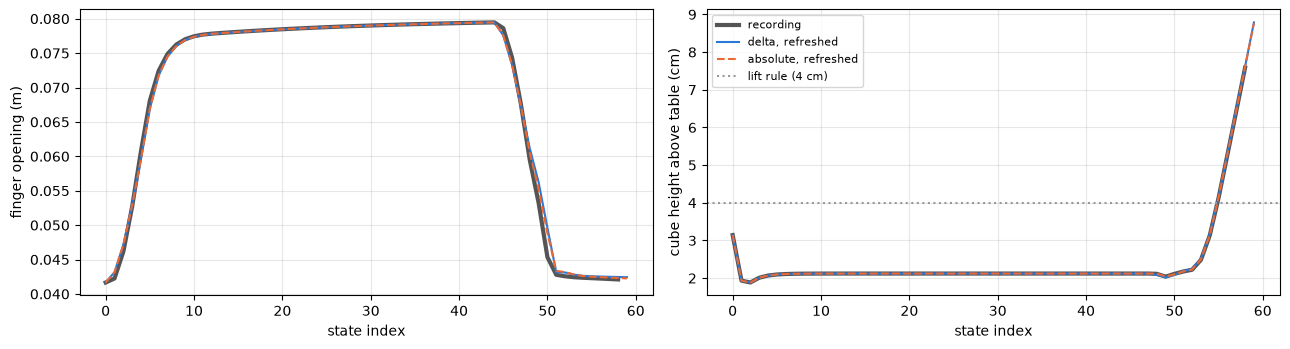

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
finger_opening = lambda s: s[:, 8] - s[:, 9]
cube_height = lambda s: (s[:, 12] - table_height) * 100
for ax, read, label in zip(axes, (finger_opening, cube_height), ("finger opening (m)", "cube height above table (cm)")):
    ax.plot(read(recording_b0["state"]), color="#555555", lw=3, label="recording")
    ax.plot(read(b0["runs"]["delta_refreshed"]["state"]), color="#2a78d6", lw=1.5, label="delta, refreshed")
    ax.plot(read(b0["runs"]["absolute_refreshed"]["state"]), color="#eb6834", lw=1.5, ls="--", label="absolute, refreshed")
    ax.set(xlabel="state index", ylabel=label)
    ax.grid(alpha=0.3)
axes[1].axhline(4, color="#999999", ls=":", label="lift rule (4 cm)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

The three lines lie almost on top of each other. Small millimetre errors do not change what the gripper and the cube do in this demonstration.

## 28. The goal log

At every step, the replay saves the controller's goal (`goal_pos` and `goal_ori`). We compare it with the stored absolute action of the same step:

- **In an absolute replay**, the goal must equal the stored action. If not, the controller received the wrong input. This is an **input problem**.
- **In a delta replay**, the gap between the goal and the stored action equals how far the robot has drifted from the recording before that step (section 25). This gap is a free measurement of drift.

So if a replay fails while its goals are correct, the cause is **tracking**: the robot did not follow correct goals.

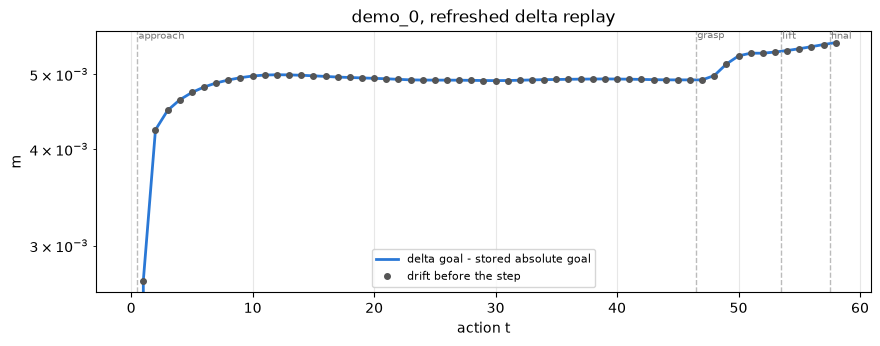

absolute_stale: largest goal gap 0.0e+00 m, 0.0e+00 rad
absolute_refreshed: largest goal gap 0.0e+00 m, 0.0e+00 rad


In [33]:
fig, ax = plt.subplots(figsize=(10, 3.4))
goal_gap = b0["goal_gaps"]["delta_refreshed"][:, 0]
# The drift before action t is the pose error after action t - 1.
drift = np.r_[np.nan, b0["errors"]["refreshed/recording_vs_delta"][:-1, 0]]
ax.semilogy(goal_gap, color="#2a78d6", lw=2, label="delta goal - stored absolute goal")
ax.semilogy(drift, "o", color="#555555", ms=4, label="drift before the step")
phase_lines(ax, b0["phase"])
ax.set(xlabel="action t", ylabel="m", title="demo_0, refreshed delta replay")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

for name in ["absolute_stale", "absolute_refreshed"]:
    print(f"{name}: largest goal gap {b0['goal_gaps'][name][:, 0].max():.1e} m, {b0['goal_gaps'][name][:, 1].max():.1e} rad")

The dots sit on the line, so the goal gap and the measured drift agree at every step. In both absolute replays, the largest gap is exactly 0, so the controller received exactly the stored goals.

## 29. Watch the replay

The video shows three views side by side: the recording (played back from its states), the delta replay, and the absolute replay. Both replays use the stale start. The differences are a fraction of a millimetre to a few millimetres, so the three views should look the same.

In [34]:
from IPython.display import Video

video_path = ROOT / "docs/continuous-replay/demo_0_replay.mp4"
if video_path.exists():
    display(Video(str(video_path), embed=True, width=900))
else:
    print("Run: MUJOCO_GL=glfw uv run python scripts/experiment_b_continuous.py")

## 30. Results across all 200 demonstrations

These numbers come from the saved results. `docs/` is not in git, so on a fresh copy of the repository you must first run:

```
MUJOCO_GL=glfw uv run python scripts/experiment_b_continuous.py --demos all --video none
```

In [35]:
experiment_b = np.load(ROOT / "docs/continuous-replay/results.npz")
b_names = list(experiment_b["demo_names"])
b_phase = experiment_b["phase"]
print(f"Recorded final state lifted: {experiment_b['outcome_recording_final'].sum()} of {len(b_names)}\n")
print(f"{'replay':20s}{'lifted':>8s}{'median final height (cm)':>27s}")
for name in EPISODES:
    print(f"{name:20s}{experiment_b[f'outcome_{name}_final'].sum():8d}{np.median(experiment_b[f'outcome_{name}_height']) * 100:27.2f}")

print("\nH17: demos where delta lifts and absolute from the same start does not")
for start in ["stale", "refreshed"]:
    broken = experiment_b[f"outcome_delta_{start}_final"] & ~experiment_b[f"outcome_absolute_{start}_final"]
    print(f"  {start}: {broken.sum()}")
gaps = max(experiment_b[f"goal_gap_absolute_{s}"].max() for s in ["stale", "refreshed"])
print(f"\nLargest goal gap in any absolute replay: {gaps:.1e}")

Recorded final state lifted: 200 of 200

replay                lifted   median final height (cm)
delta_stale              199                       8.97
delta_refreshed          196                       8.98
absolute_stale           199                       8.97
absolute_refreshed       199                       8.97

H17: demos where delta lifts and absolute from the same start does not
  stale: 0
  refreshed: 0

Largest goal gap in any absolute replay: 0.0e+00


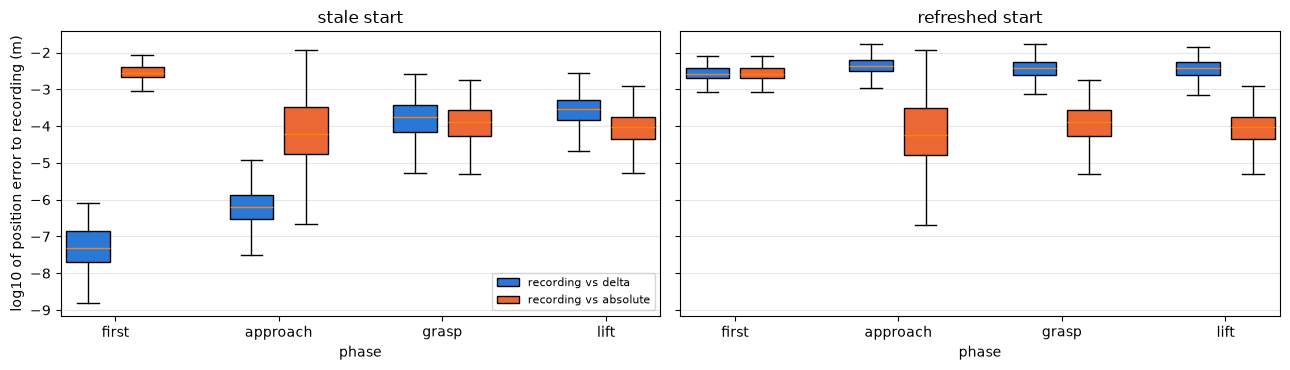

In [36]:
phases = ["first", "approach", "grasp", "lift"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, start in zip(axes, ["stale", "refreshed"]):
    data, positions, colors = [], [], []
    for i, phase in enumerate(phases):
        for k, (pair, color) in enumerate((("recording_vs_delta", "#2a78d6"), ("recording_vs_absolute", "#eb6834"))):
            values = experiment_b[f"errors_{start}_{pair}"][:, 0][b_phase == phase]
            data.append(np.log10(np.maximum(values, 1e-16)))
            positions.append(i * 3 + k)
            colors.append(color)
    parts = ax.boxplot(data, positions=positions, widths=0.8, patch_artist=True, showfliers=False)
    for patch, color in zip(parts["boxes"], colors):
        patch.set_facecolor(color)
    ax.set_xticks([i * 3 + 0.5 for i in range(len(phases))], phases)
    ax.set(title=f"{start} start", xlabel="phase")
    ax.grid(alpha=0.3, axis="y")
axes[0].set_ylabel("log10 of position error to recording (m)")
axes[0].legend(parts["boxes"][:2], ["recording vs delta", "recording vs absolute"], fontsize=8)
plt.tight_layout()
plt.show()

Each box covers the middle half of the steps in that phase, and the line inside is the median.

- **Stale start:** the delta replay copies the recording until contact (median 6.5e-7 m). The absolute replay starts about 3 mm off and needs the approach to come back.
- **Refreshed start:** the delta replay stays about 4 mm off for the whole episode. The absolute replay comes back during the approach. During grasp and lift it is closer to the recording than the delta replay.
- **Grasp and lift:** for the stale start, both replays are a few tenths of a millimetre off, which is the contact sensitivity from Part 3.

## 31. The failed replays

Four demonstrations have at least one replay that does not lift the cube:

| Demo | Failed replays | Cause |
| --- | --- | --- |
| `demo_40`, `demo_115`, `demo_118` | `delta_refreshed` only | The refreshed delta replay reaches the cube a few millimetres off, and the cube slips out during the lift. Both absolute replays lift the cube. |
| `demo_177` | all four | The cube slips at the grasp in every replay. |

`demo_177` is the important case. Its stale delta replay copies the recording closely until contact, and it still fails. So the conversion did not cause it. The grasp in this demonstration is so close to slipping that the tiny contact differences from Part 3 change the result. This is a limit of replaying a recording in the simulator.

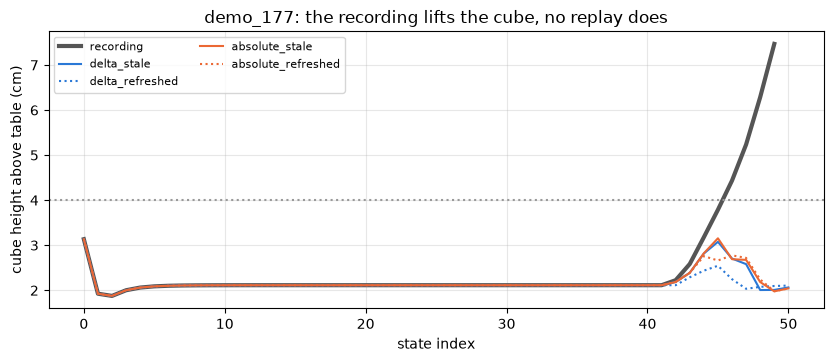

In [37]:
with h5py.File(source_path, "r") as f, h5py.File(ABS_PATH, "r") as g:
    b177 = run_demo(replay_envs, f["data/demo_177"], g["data/demo_177"], video=False)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(cube_height(b177["recording"]["state"]), color="#555555", lw=3, label="recording")
styles = {"delta_stale": ("#2a78d6", "-"), "delta_refreshed": ("#2a78d6", ":"), "absolute_stale": ("#eb6834", "-"), "absolute_refreshed": ("#eb6834", ":")}
for name, (color, ls) in styles.items():
    ax.plot(cube_height(b177["runs"][name]["state"]), color=color, ls=ls, lw=1.5, label=name)
ax.axhline(4, color="#999999", ls=":")
ax.set(xlabel="state index", ylabel="cube height above table (cm)", title="demo_177: the recording lifts the cube, no replay does")
ax.legend(fontsize=8, ncol=2)
ax.grid(alpha=0.3)
plt.show()

## 32. Which `t = 0` goal should the file keep?

The absolute replays start about 3 mm off the recording. The cause is the stored `t = 0` goal. There are two possible goals for the first step:

| Goal | Formula | Meaning |
| --- | --- | --- |
| **Current goal** (in the file) | actual start pose + 0.05 × first delta | the target from where the gripper really is |
| **Stale goal** | nominal start pose + 0.05 × first delta | the target the controller really used in the recording |

The **actual start pose** is the true gripper pose at `s_0`. It is different in each demonstration, because robosuite adds random noise to the joint angles at reset. The **nominal start pose** is the robot's default pose, without that noise. It is the same in all 200 demonstrations.

The stale goal would reproduce the recorded `s_1` exactly. But is it a good point for curve fitting? The next cell computes both goals for all 200 demonstrations and compares the jump to the `t = 1` goal with normal jumps between goals.

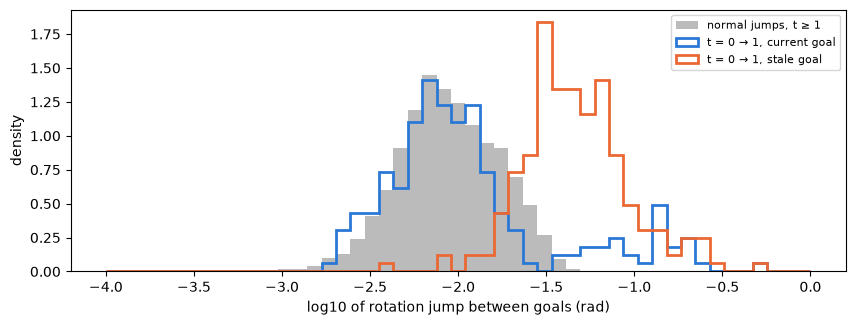

Median rotation jump: normal 0.0087 rad | current t = 0 0.0088 rad | stale t = 0 0.0431 rad


In [38]:
current_jump, stale_jump, normal_jump = [], [], []
with h5py.File(source_path, "r") as f, h5py.File(ABS_PATH, "r") as g:
    for key in demo_keys(f["data"]):
        load_demo_model(env, f[f"data/{key}"])
        stale = arm_controller(env)
        # Right after a model load, set_goal builds the goal from the nominal start pose.
        stale.set_goal(f[f"data/{key}/actions"][0, :6])
        stored = Rotation.from_rotvec(g[f"data/{key}/actions"][:, 3:6])
        current_jump.append((stored[0].inv() * stored[1]).magnitude())
        stale_jump.append((Rotation.from_matrix(stale.goal_ori).inv() * stored[1]).magnitude())
        normal_jump.extend((stored[1:-1].inv() * stored[2:]).magnitude())

fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.linspace(-4, 0, 50)
ax.hist(np.log10(normal_jump), bins=bins, density=True, color="#bbbbbb", label="normal jumps, t ≥ 1")
ax.hist(np.log10(current_jump), bins=bins, density=True, histtype="step", lw=2, color="#2a78d6", label="t = 0 → 1, current goal")
ax.hist(np.log10(stale_jump), bins=bins, density=True, histtype="step", lw=2, color="#eb6834", label="t = 0 → 1, stale goal")
ax.set(xlabel="log10 of rotation jump between goals (rad)", ylabel="density")
ax.legend(fontsize=8)
plt.show()
print(f"Median rotation jump: normal {np.median(normal_jump):.4f} rad | current t = 0 {np.median(current_jump):.4f} rad | stale t = 0 {np.median(stale_jump):.4f} rad")

The current goal makes a rotation jump of the same size as a normal jump (median 0.0088 rad against 0.0087 rad). The stale goal makes a jump about 5 times larger (0.043 rad). It is a point off the path of goals:

- A Bézier curve fitted through all the goals would bend to reach it.
- A policy trained on it would learn to aim at the nominal pose on its first step. At deployment the robot starts at a noisy actual pose, so this aim would be wrong.

The current goal causes only the 3 mm error at the start of a replay. That error fades during the approach and caused no failure in 200 demonstrations.

**Decision:** the file keeps the current goal. It is the better label for curve fitting and policy training. The cost is that a replay does not reproduce `s_1` exactly.

## 33. What is settled, what is open, and one exercise

**Settled**
- The absolute controller receives exactly the stored goals (largest gap 0).
- In all 200 demonstrations, absolute replay lifts the cube whenever delta replay from the same start lifts it (H17).
- With the refreshed start, absolute replay is more reliable than delta replay: 199 lifts against 196.
- The recording used the stale first step. The stale delta replay copies it until contact.
- The file keeps the current `t = 0` goal.

**Open**
- `demo_177` fails in every replay. A policy trained on it learns from a grasp that the simulator does not reproduce reliably.
- How to treat `t = 0` and the contact steps in curve fitting is not yet decided.

**Common mistakes**
- Expecting delta and absolute replays to match closely. Delta keeps drift, and absolute removes it.
- Using the one-step `1e-8` limits on whole episodes.
- Treating a failed replay as a conversion error without first checking the goal log and the stale delta replay.
- Using `next_obs[-1]` as the target of the final step.

**Exercise.** In the saved results, find the demonstration and step where the refreshed absolute replay is farthest from the recording during the approach phase. Is that step near the start of the episode?

In [39]:
# One possible answer.
errors = experiment_b["errors_refreshed_recording_vs_absolute"][:, 0]
approach = b_phase == "approach"
worst = np.flatnonzero(approach)[errors[approach].argmax()]
print(f"{experiment_b['demo'][worst]} at t = {experiment_b['t'][worst]}: {errors[worst] * 1000:.2f} mm")

demo_115 at t = 1: 11.45 mm
